# Data Visualization
Figures describing the dataset. Figures are saved to `figures/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

figures_folder = Path("./figures")
figures_folder.mkdir(exist_ok=True)

# the full dataset, before sampling (the experiments use a sample of it, embeddings_sampled.pkl)
df = pd.read_pickle("./unsampled_dataframe.pkl")
LABEL_COL = "Party_orientation"
print(f"{len(df):,} sentences")

1,019,921 sentences


## Original class distribution
The nine original party-orientation labels in the full (unsampled) dataset, ordered along the political spectrum. In the experiments they are merged into
Left (red) and Right (blue), and Centre (grey) is dropped.

In [2]:
# labels in spectrum order, with their colour: red = merged into Left, blue = merged into Right, grey = dropped
# (darker = further from the centre)
SPECTRUM = {
    "Centre-left to left":    "#c13534",
    "Centre-left":            "#e34948",
    "Centre to centre-left":  "#f2a3a2",
    "Centre":                 "#b4b2ab",
    "Centre to centre-right": "#86b6ef",
    "Centre-right":           "#5598e7",
    "Right":                  "#2a78d6",
    "Right to far-right":     "#1c5cab",
    "Far-right":              "#0d366b",
}

counts = df[LABEL_COL].value_counts().reindex(list(SPECTRUM))
assert counts.notna().all() and counts.sum() == len(df), "unexpected labels in the data"
total = counts.sum()
counts.to_frame("sentences").assign(share=(counts / total * 100).round(1))

,sentences,share
Party_orientation,,
Centre-left to left,26813,2.6
Centre-left,239590,23.5
Centre to centre-left,116326,11.4
Centre,9113,0.9
Centre to centre-right,2140,0.2
Centre-right,204621,20.1
Right,119070,11.7
Right to far-right,290861,28.5
Far-right,11387,1.1


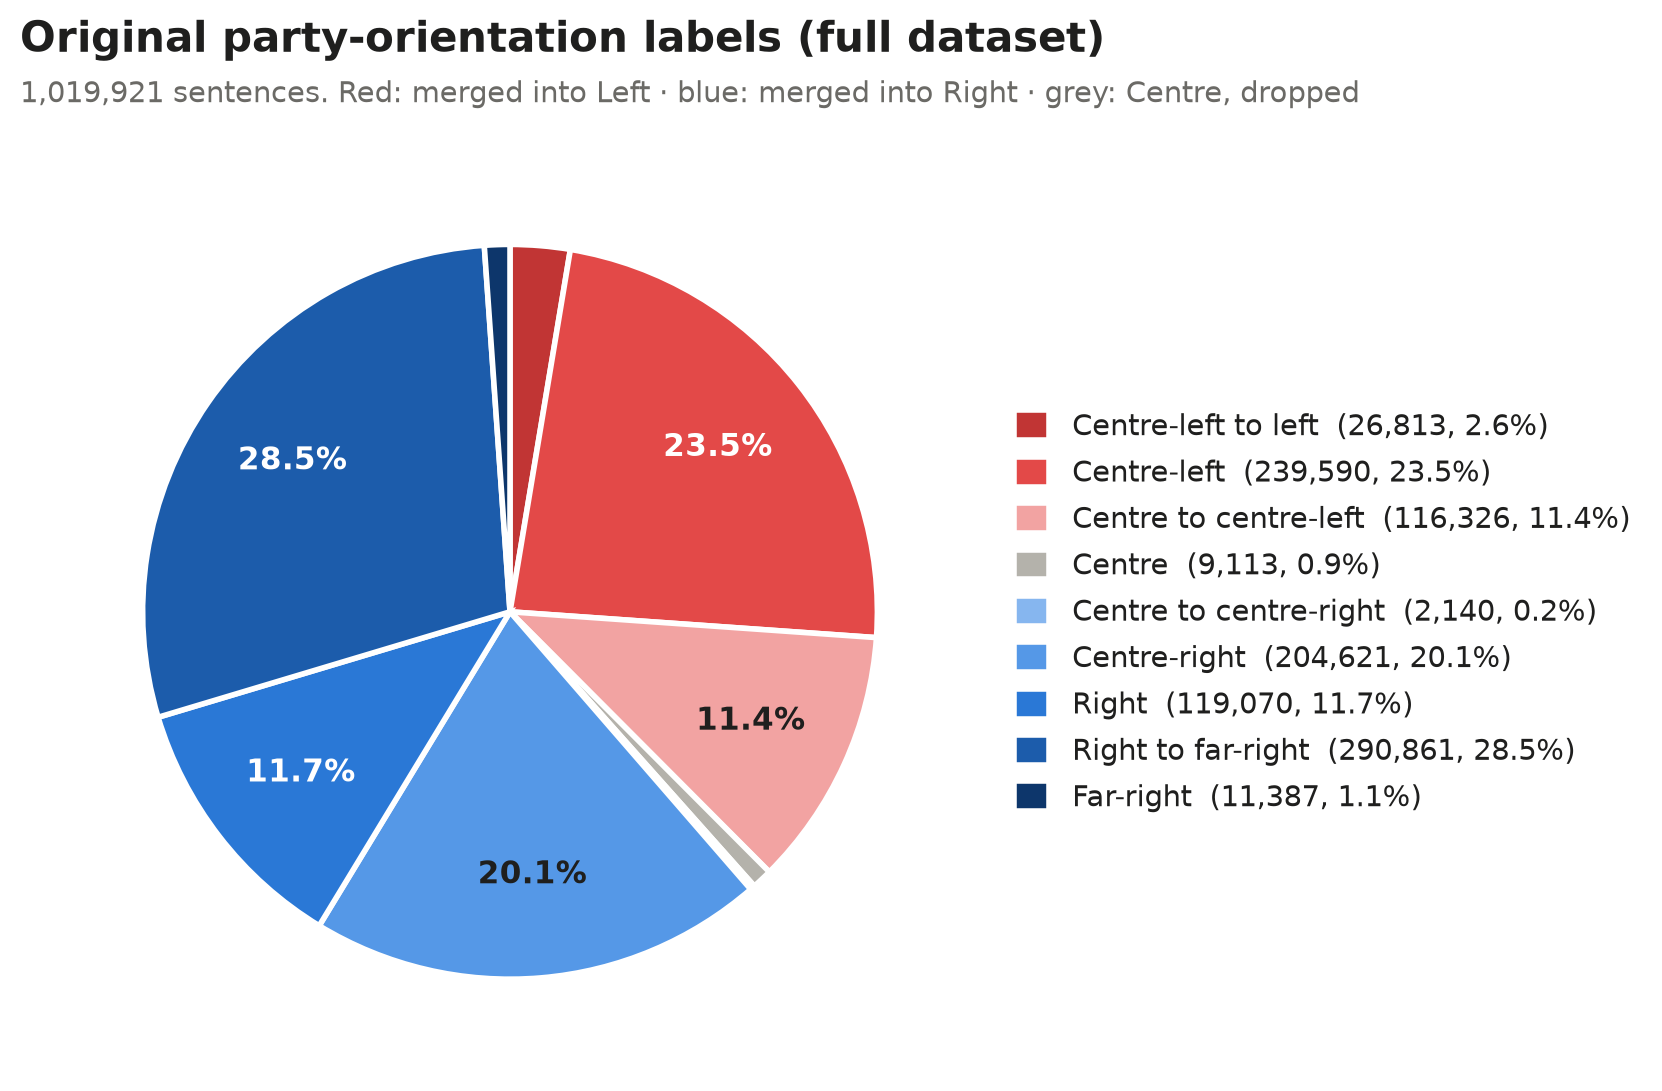

In [3]:
ink, muted = "#1f1f1e", "#6b6a66"

fig, ax = plt.subplots(figsize=(10, 5.6), dpi=200)
wedges, _, pct_labels = ax.pie(
    counts,
    colors=list(SPECTRUM.values()),
    startangle=90,
    counterclock=False,                       # clockwise from the top, left to right along the spectrum
    wedgeprops=dict(edgecolor="white", linewidth=2),
    autopct=lambda p: f"{p:.1f}%" if p >= 5 else "",  # print shares only on slices large enough to hold them
    pctdistance=0.72,
    textprops=dict(color="white", fontsize=11, fontweight="bold"),
)
ax.set_aspect("equal")
# dark text on light slices, white text on dark ones, so the shares stay readable
for label, colour in zip(pct_labels, SPECTRUM.values()):
    r, g, b = (int(colour[i:i + 2], 16) / 255 for i in (1, 3, 5))
    label.set_color(ink if 0.2126 * r + 0.7152 * g + 0.0722 * b > 0.5 else "white")
ax.legend(
    wedges,
    [f"{label}  ({n:,}, {n / total * 100:.1f}%)" for label, n in counts.items()],
    loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False,
    fontsize=10.5, labelcolor=ink, handlelength=1.2, handleheight=1.2,
)
fig.text(0.04, 0.95, "Original party-orientation labels (full dataset)", fontsize=15, fontweight="bold", color=ink)
fig.text(0.04, 0.905, f"{total:,} sentences. Red: merged into Left · blue: merged into Right · grey: Centre, dropped",
         fontsize=10.5, color=muted)
fig.subplots_adjust(left=0.02, right=0.55, top=0.86, bottom=0.04)
fig.savefig(figures_folder / "class_distribution_original.png", bbox_inches="tight", facecolor="white")
plt.show()